# TP final IA II - Paso 2 (versión 2): dataset Sentinel-2 cada 10 días, 6 campañas, 4 clases y clima

Arma el dataset para los notebooks 03 (solo imágenes) y 04 (imágenes + clima). Respecto de la versión 1:

| | Versión 1 | Versión 2 |
|---|---|---|
| Campañas | 2022/23 y 2023/24 | **2019/20 a 2024/25 (6)** |
| Clases | Maíz, soja 1ra, soja 2da | **+ Otros** (mitad otros cultivos, mitad no agrícola) |
| Imágenes | 1 por mes (9) | **1 cada 10 días (27)** |
| Bandas | 6 | **10**: se suma el borde rojo (B5, B6, B7, B8A) |
| Parche | 32 x 32 px (320 m) | **16 x 16 px (160 m)** |
| Puntos por departamento | Sin límite (uno tenía 604) | **Tope por departamento**, para que todos pesen parecido |
| Clima | No | **Lluvia y temperatura cada 10 días** (ERA5-Land), solo para el 04 |

**Por qué el parche más chico:** con 6 campañas, 27 fechas y 10 bandas, parches de 32 x 32 ocuparían unos 12 GB y Colab no los puede cargar; con 16 x 16 son unos 3 GB. Además, en el 03 la prueba de píxeles permutados mostró que la red no usa la forma dentro del parche. La pureza se sigue exigiendo en una ventana de ~330 m, así que el parche queda bien adentro del lote.

**Qué guarda** (en `MyDrive/TP_final_IA2/dataset_v2/`):
- `dataset_cultivos.npz`:
  - `X` de forma `(N, 27, 16, 16, 10)` en `uint16`.
  - `y_cultivo`: 0 = Maíz, 1 = Soja 1ra, 2 = Soja 2da, 3 = Otros.
  - `y_rinde`: rinde sobre superficie sembrada, `NaN` si no hay dato (la clase Otros nunca tiene).
  - `relleno` `(N, 27)`: fracción de cada parche que estaba nublada y se interpoló.
  - `clima` `(N, 27, 3)`: lluvia en mm, temperatura media y temperatura máxima media en °C.
  - `id`.
- `dataset_meta.csv`: campaña, clase, subclase, coordenadas, provincia, departamento, `grupo`, los dos rindes.

**Antes de correrlo:**
1. Correr el **notebook 01 versión 2**: este lee las etiquetas de `datos_inta/v2/`.
2. Correr primero con `PRUEBA = True` (144 puntos, unos 15 minutos) y revisar las salidas. Después `PRUEBA = False` (estimado: 2 a 3 horas, casi todo es la descarga).

**Si Colab se corta:** volver a ejecutar todo. El sorteo, el cruce con departamentos, el clima y los lotes de parches ya bajados quedan en Drive y se retoma desde donde quedó. **Si cambiás algo del sorteo** (cantidad de puntos, pureza, tope por departamento, zona), borrá la carpeta `dataset_v2/` entera.

In [16]:
PRUEBA = False   # True: 144 puntos para probar el circuito. False: el dataset completo (~19.200 puntos)

import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/TP_final_IA2'
    EN_COLAB = True
except ImportError:                                  # fuera de Colab
    BASE = os.environ.get('TP_BASE', 'TP_final_IA2')
    EN_COLAB = False

ETIQ   = f'{BASE}/datos_inta/v2'
SALIDA = f'{BASE}/dataset_v2_prueba' if PRUEBA else f'{BASE}/dataset_v2'
CSV_RINDES = f'{BASE}/rendimientos_pampeana_2018-2025.csv'
os.makedirs(SALIDA, exist_ok=True)

assert os.path.exists(CSV_RINDES), 'Falta rendimientos_pampeana_2018-2025.csv en MyDrive/TP_final_IA2/'
print('Guardando en', SALIDA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Guardando en /content/drive/MyDrive/TP_final_IA2/dataset_v2


In [17]:
%pip -q install rasterio pyproj

## 1. Conexión con Earth Engine

La primera vez abre una ventana para autorizar la cuenta. Usá la misma con la que se registró el proyecto `tp-cultivos-ia2`.

In [18]:
import ee
ee.Authenticate()
ee.Initialize(project='tp-cultivos-ia2')
print(ee.String('Earth Engine conectado').getInfo())

Earth Engine conectado


## 2. Parámetros

In [19]:
import datetime

CAMPANAS = {c: {'tif': f'{ETIQ}/etiquetas_{c}.tif', 'inicio': f'20{c[2:4]}-09-01', 'csv': f'20{c[2:4]}/{c[5:7]}'}
            for c in ['2019_20', '2020_21', '2021_22', '2022_23', '2023_24', '2024_25']}
for c, cfg in CAMPANAS.items():
    assert os.path.exists(cfg['tif']), f'Falta {cfg["tif"]}: corré el notebook 01 versión 2'

CLASES = {0: 'Maíz', 1: 'Soja 1ra', 2: 'Soja 2da', 3: 'Otros'}
# De qué etiqueta del 01 sale cada clase y qué parte de los puntos de la clase aporta
FUENTES = {0: {0: 1.0}, 1: {1: 1.0}, 2: {2: 1.0}, 3: {3: 0.5, 4: 0.5}}     # Otros = mitad otros cultivos (3), mitad no agrícola (4)
NOMBRE_SUB = {0: 'Maíz', 1: 'Soja 1ra', 2: 'Soja 2da', 3: 'Otros cultivos', 4: 'No agrícola'}

N_POR_CLASE   = 6 if PRUEBA else 800   # puntos por clase y por campaña: 4 clases x 6 campañas x 800 = 19.200
MAX_POR_DEPTO = 2 if PRUEBA else 40    # tope de puntos de una misma clase, campaña y departamento
CANDIDATOS_X  = 3                      # se preseleccionan 3 veces más candidatos para poder aplicar el tope
PUREZA_FILAS, PUREZA_COLS = 11, 13     # ventana de ~330 m x 325 m en el mapa del INTA (pixel de ~30 x 25 m)
PUREZA_MIN    = 0.9
SEPARACION_M  = 500
PIX_ALTO_M, PIX_ANCHO_M = 30.0, 25.0
PATCH         = 16                     # 16 x 16 píxeles de 10 m = 160 m
BANDAS        = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']   # azul, verde, rojo, 3 de borde rojo, NIR, NIR angosto, SWIR1, SWIR2
CS_UMBRAL     = 0.6                    # Cloud Score+: se descarta todo pixel con puntaje menor
RINDE_TARGET  = 'rinde_sembrado'
SUP_MIN_HA    = 200
SEED          = 42

def periodos(inicio):
    # 27 períodos de septiembre a mayo: días 1-10, 11-20 y 21-fin de cada mes (fin exclusivo, como filterDate)
    a, out = datetime.date.fromisoformat(inicio), []
    for k in range(9):
        y, m = a.year + (a.month - 1 + k) // 12, (a.month - 1 + k) % 12 + 1
        fin_mes = datetime.date(y + (m == 12), m % 12 + 1, 1)
        for d0, d1 in [(1, 11), (11, 21), (21, None)]:
            out.append((datetime.date(y, m, d0).isoformat(), (datetime.date(y, m, d1) if d1 else fin_mes).isoformat()))
    return out

T = len(periodos('2020-09-01'))
ETIQ_T = [f'{d[8:10]}/{d[5:7]}' for d, _ in periodos('2020-09-01')]     # etiqueta de cada período: día/mes de inicio
NOMBRES_BANDAS = [f't{t:02d}_{b}' for t in range(T) for b in BANDAS]
print(f'{T} períodos por campaña, del {periodos("2020-09-01")[0][0][5:]} al {periodos("2020-09-01")[-1][1][5:]} (exclusive)')
print(f'Tamaño estimado de X: {4 * N_POR_CLASE * len(CAMPANAS) * T * PATCH * PATCH * len(BANDAS) * 2 / 1e9:.2f} GB')

27 períodos por campaña, del 09-01 al 06-01 (exclusive)
Tamaño estimado de X: 2.65 GB


## 3. Sorteo de candidatos puros y separados

Igual que en la versión 1: para cada campaña y cada clase se sortean píxeles al azar y se quedan los que cumplen la **pureza** (90 % de la ventana de ~330 m del mismo tipo) y la **separación** (nada a menos de 500 m). La diferencia es que acá se juntan **3 veces más** candidatos de los necesarios, para poder aplicar después el tope por departamento.

Para la clase Otros se sortean por separado "otros cultivos" y "no agrícola", y cada candidato tiene que ser puro de su propio tipo.

In [20]:
import numpy as np
import pandas as pd
import rasterio

RUTA_CAND = f'{SALIDA}/candidatos_gaul.csv'

def sortear_candidatos():
    rng = np.random.default_rng(SEED)
    hf, hc = PUREZA_FILAS // 2, PUREZA_COLS // 2
    celda_f, celda_c = int(np.ceil(SEPARACION_M / PIX_ALTO_M)), int(np.ceil(SEPARACION_M / PIX_ANCHO_M))
    filas = []
    for camp, cfg in CAMPANAS.items():
        with rasterio.open(cfg['tif']) as src:
            lab, tr = src.read(1), src.transform
        H, W = lab.shape
        grilla = {}
        for clase, fuentes in FUENTES.items():
            for sub, frac in fuentes.items():
                meta_n = int(np.ceil(N_POR_CLASE * frac)) * CANDIDATOS_X
                idx = np.flatnonzero(lab == sub)
                if len(idx) == 0:
                    print(f'{camp} | {NOMBRE_SUB[sub]}: no hay píxeles de esta clase'); continue
                cand = rng.choice(idx, size=min(len(idx), meta_n * 60), replace=False)
                rr, cc = np.unravel_index(cand, lab.shape)
                dentro = (rr >= hf) & (cc >= hc) & (rr < H - hf) & (cc < W - hc)
                elegidos = []
                for r, c in zip(rr[dentro], cc[dentro]):
                    gf, gc = r // celda_f, c // celda_c
                    if any(np.hypot((r - r2) * PIX_ALTO_M, (c - c2) * PIX_ANCHO_M) < SEPARACION_M
                           for df in (-1, 0, 1) for dc in (-1, 0, 1) for (r2, c2) in grilla.get((gf + df, gc + dc), [])):
                        continue
                    if (lab[r - hf:r + hf + 1, c - hc:c + hc + 1] == sub).mean() >= PUREZA_MIN:
                        grilla.setdefault((gf, gc), []).append((r, c))
                        elegidos.append((r, c))
                        if len(elegidos) == meta_n:
                            break
                for r, c in elegidos:
                    lon, lat = tr * (c + 0.5, r + 0.5)
                    filas.append({'campana': camp, 'clase': clase, 'cultivo': CLASES[clase], 'subclase': sub,
                                  'lon': lon, 'lat': lat})
                print(f'{camp} | {NOMBRE_SUB[sub]:14s}: {len(elegidos):5d} candidatos (se buscaban {meta_n})')
        del lab
    p = pd.DataFrame(filas)
    p.insert(0, 'id_cand', range(len(p)))
    return p

def cruzar_gaul(p):
    try:
        gaul = ee.FeatureCollection('FAO/GAUL/2015/level2'); gaul.limit(1).size().getInfo()
    except Exception:
        gaul = ee.FeatureCollection('FAO/GAUL_SIMPLIFIED_500m/2015/level2')
    gaul = gaul.filter(ee.Filter.eq('ADM0_NAME', 'Argentina'))

    def lote(df):
        fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([r.lon, r.lat]), {'id_cand': int(r.id_cand)})
                                   for r in df.itertuples()])
        unidos = ee.Join.saveFirst('d').apply(fc, gaul, ee.Filter.intersects(leftField='.geo', rightField='.geo'))
        unidos = unidos.map(lambda f: ee.Feature(None, {
            'id_cand': f.get('id_cand'),
            'prov_gaul': ee.Feature(f.get('d')).get('ADM1_NAME'),
            'dep_gaul':  ee.Feature(f.get('d')).get('ADM2_NAME')}))
        return [x['properties'] for x in unidos.getInfo()['features']]

    res = []
    for i in range(0, len(p), 1000):
        res += lote(p.iloc[i:i + 1000])
        print(f'  departamentos: {min(i + 1000, len(p))}/{len(p)}', end='\r')
    return p.merge(pd.DataFrame(res), on='id_cand', how='left')

if os.path.exists(RUTA_CAND):
    cand = pd.read_csv(RUTA_CAND)
    print('Candidatos cargados de Drive:', len(cand))
else:
    cand = cruzar_gaul(sortear_candidatos())
    cand.to_csv(RUTA_CAND, index=False)
    print('\nCandidatos y departamentos guardados en', RUTA_CAND)
print('Candidatos sin departamento (fuera de los polígonos, se descartan):', cand.dep_gaul.isna().sum())

2019_20 | Maíz          :  2400 candidatos (se buscaban 2400)
2019_20 | Soja 1ra      :  2400 candidatos (se buscaban 2400)
2019_20 | Soja 2da      :  2400 candidatos (se buscaban 2400)
2019_20 | Otros cultivos:   213 candidatos (se buscaban 1200)
2019_20 | No agrícola   :  1200 candidatos (se buscaban 1200)
2020_21 | Maíz          :  2400 candidatos (se buscaban 2400)
2020_21 | Soja 1ra      :  2400 candidatos (se buscaban 2400)
2020_21 | Soja 2da      :  2400 candidatos (se buscaban 2400)
2020_21 | Otros cultivos:   802 candidatos (se buscaban 1200)
2020_21 | No agrícola   :  1200 candidatos (se buscaban 1200)
2021_22 | Maíz          :  2400 candidatos (se buscaban 2400)
2021_22 | Soja 1ra      :  2400 candidatos (se buscaban 2400)
2021_22 | Soja 2da      :  2400 candidatos (se buscaban 2400)
2021_22 | Otros cultivos:   686 candidatos (se buscaban 1200)
2021_22 | No agrícola   :  1200 candidatos (se buscaban 1200)
2022_23 | Maíz          :  2400 candidatos (se buscaban 2400)
2022_23 

## 4. Selección final con tope por departamento

De los candidatos de cada campaña y tipo se toman, en el orden del sorteo, los primeros que no superen `MAX_POR_DEPTO` puntos en su departamento. Si con el tope no se llega a la cantidad buscada, se completa sin tope y se avisa.

En la versión 1, los 5 departamentos más grandes tenían el 47 % de los parches. Con el tope, cada departamento pesa más parecido, que es lo que importa para el rinde: **cada departamento es un único dato de rinde**.

Esta lista fija los puntos (`puntos.csv`): los parches se bajan para esa lista, en ese orden.

In [21]:
RUTA_PUNTOS = f'{SALIDA}/puntos.csv'

def elegir(cand):
    c = cand.dropna(subset=['dep_gaul']).copy()
    c['depto_gaul'] = c.prov_gaul + '|' + c.dep_gaul
    filas, avisos = [], []
    for (camp, clase, sub), g in c.groupby(['campana', 'clase', 'subclase'], sort=False):
        meta_n = int(np.ceil(N_POR_CLASE * FUENTES[clase][sub]))
        cuenta, tomados = {}, []
        for i, d in zip(g.index, g.depto_gaul):            # g ya está en el orden aleatorio del sorteo
            if cuenta.get(d, 0) < MAX_POR_DEPTO:
                cuenta[d] = cuenta.get(d, 0) + 1
                tomados.append(i)
                if len(tomados) == meta_n:
                    break
        if len(tomados) < meta_n:                           # no alcanzó con el tope: se completa sin tope
            extra = [i for i in g.index if i not in set(tomados)][:meta_n - len(tomados)]
            avisos.append(f'{camp} | {NOMBRE_SUB[sub]}: con el tope hubo {len(tomados)}, se completó con {len(extra)} sin tope')
            tomados += extra
        if len(tomados) < meta_n:
            avisos.append(f'{camp} | {NOMBRE_SUB[sub]}: solo hay {len(tomados)} candidatos de {meta_n}')
        filas.append(c.loc[tomados])
    p = pd.concat(filas).sort_values(['campana', 'id_cand']).reset_index(drop=True)
    p.insert(0, 'id', range(len(p)))
    return p.drop(columns='depto_gaul'), avisos

if os.path.exists(RUTA_PUNTOS):
    puntos_gaul = pd.read_csv(RUTA_PUNTOS)
    print('Puntos cargados de Drive:', len(puntos_gaul))
else:
    puntos_gaul, avisos = elegir(cand)
    puntos_gaul.to_csv(RUTA_PUNTOS, index=False)
    for a in avisos:
        print('AVISO:', a)
print('\nPuntos por campaña y clase:')
print(puntos_gaul.groupby(['campana', 'cultivo']).size().unstack().reindex(columns=list(CLASES.values())))
d = puntos_gaul.groupby(['prov_gaul', 'dep_gaul']).size().sort_values(ascending=False)
print(f'\nDepartamentos: {len(d)} | los 5 más grandes tienen el {100 * d.head(5).sum() / len(puntos_gaul):.0f} % de los puntos (en la versión 1: 47 %)')

AVISO: 2019_20 | Otros cultivos: con el tope hubo 121, se completó con 92 sin tope
AVISO: 2019_20 | Otros cultivos: solo hay 213 candidatos de 400
AVISO: 2022_23 | Otros cultivos: con el tope hubo 79, se completó con 0 sin tope
AVISO: 2022_23 | Otros cultivos: solo hay 79 candidatos de 400

Puntos por campaña y clase:
cultivo  Maíz  Soja 1ra  Soja 2da  Otros
campana                                 
2019_20   800       800       800    613
2020_21   800       800       800    800
2021_22   800       800       800    800
2022_23   800       800       800    479
2023_24   800       800       800    800
2024_25   800       800       800    800

Departamentos: 37 | los 5 más grandes tienen el 25 % de los puntos (en la versión 1: 47 %)


## 5. Departamento normalizado y rinde (MAGyP)

Igual que en la versión 1 (el rinde sobre superficie sembrada está explicado ahí), con dos cambios:
- **La clase Otros no tiene rinde** (`NaN`), y los puntos de maíz o soja sin dato de rinde **no se descartan**: sirven para aprender el cultivo. En el 03 el rinde faltante lleva peso 0 en la pérdida.
- Se controla que, para maíz y soja, al menos el 80 % de los puntos tenga rinde. Si no, casi seguro hay nombres de departamento que no coinciden entre GAUL y el MAGyP: se agregan a `ALIAS`.

In [22]:
import unicodedata

def norm(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().upper()
    return ' '.join(s.replace('-', ' ').replace('.', ' ').split())

ALIAS = {
    ('BUENOS AIRES', 'BARTOLOME MITRE'): 'ARRECIFES',
}

puntos = puntos_gaul.copy()
puntos['provincia'] = puntos.prov_gaul.map(norm)
puntos['departamento'] = [ALIAS.get((p, norm(d)), norm(d)) for p, d in zip(puntos.provincia, puntos.dep_gaul)]
puntos['grupo'] = puntos.provincia + '|' + puntos.departamento
puntos['cultivo_n'] = puntos.cultivo.map(norm)
puntos['campana_csv'] = puntos.campana.map({k: v['csv'] for k, v in CAMPANAS.items()})

rin = pd.read_csv(CSV_RINDES, encoding='utf-8-sig')
rin['provincia'] = rin.provincia.map(norm)
rin['departamento'] = rin.departamento.map(norm)
rin['cultivo_n'] = rin.cultivo.map(norm)
rin = rin.rename(columns={'campana': 'campana_csv'})
rin = rin[rin.sup_sembrada_ha >= SUP_MIN_HA].copy()
rin['rinde_cosechado'] = rin.rendimiento_kg_ha.astype(float).where(rin.sup_cosechada_ha > 0)
rin['rinde_sembrado'] = rin.produccion_tn * 1000 / rin.sup_sembrada_ha
rin['frac_cosechada'] = rin.sup_cosechada_ha / rin.sup_sembrada_ha

claves = ['provincia', 'departamento', 'cultivo_n', 'campana_csv']
assert not rin.duplicated(claves).any(), 'Hay filas duplicadas en el CSV de rindes'
assert set(CAMPANAS[c]['csv'] for c in CAMPANAS) <= set(rin.campana_csv), 'Faltan campañas en el CSV de rindes'

puntos = puntos.merge(rin[claves + ['rinde_sembrado', 'rinde_cosechado', 'frac_cosechada', 'sup_sembrada_ha']],
                      on=claves, how='left')
otros = puntos.clase == 3
puntos.loc[otros, ['rinde_sembrado', 'rinde_cosechado', 'frac_cosechada', 'sup_sembrada_ha']] = np.nan
puntos['y_rinde'] = puntos[RINDE_TARGET]

sin = puntos[~otros & puntos.rinde_sembrado.isna()]
if len(sin):
    print('Puntos de maíz o soja sin rinde (departamento sin dato, poca superficie o nombre distinto -> revisar ALIAS):')
    print(sin.groupby(['provincia', 'departamento', 'cultivo']).size().sort_values(ascending=False).head(20).to_string(), '\n')
con_rinde = puntos[~otros].groupby('cultivo').y_rinde.apply(lambda s: s.notna().mean())
print('Fracción de puntos con rinde:', con_rinde.round(3).to_dict())
if not PRUEBA:
    assert con_rinde.min() > 0.8, 'Más del 20 % de los puntos de un cultivo no tiene rinde: revisar ALIAS'

print('\nDepartamentos distintos:', puntos.grupo.nunique())
print('\nRinde medio sobre superficie sembrada (kg/ha) por campaña y cultivo:')
print(puntos[~otros].groupby(['campana', 'cultivo']).rinde_sembrado.mean().unstack().round(0))

Fracción de puntos con rinde: {'Maíz': 1.0, 'Soja 1ra': 1.0, 'Soja 2da': 1.0}

Departamentos distintos: 37

Rinde medio sobre superficie sembrada (kg/ha) por campaña y cultivo:
cultivo    Maíz  Soja 1ra  Soja 2da
campana                            
2019_20  7160.0    3669.0    2397.0
2020_21  7202.0    3358.0    2304.0
2021_22  6027.0    3167.0    2312.0
2022_23  3264.0    1569.0     637.0
2023_24  7032.0    3775.0    2827.0
2024_25  7282.0    3719.0    2943.0


## 6. Composites de Sentinel-2 cada 10 días

Para cada campaña se arman 27 imágenes "limpias", una por período de 10 días (del 1 al 10, del 11 al 20 y del 21 a fin de mes, de septiembre a mayo). Cada una es la **mediana** de las pasadas del satélite en ese período, después de sacar nubes, neblina y sombras con **Cloud Score+**.

En 10 días el satélite pasa unas 2 veces, así que va a haber más huecos que con los composites mensuales: un período en el que las dos pasadas estuvieron nubladas queda vacío y se interpola en la sección 9. El porcentaje rellenado por período se informa ahí.

Las bandas de borde rojo (B5, B6, B7, B8A) tienen píxeles de 20 m; Earth Engine las entrega en la misma grilla de 10 m que las demás.

In [23]:
REGION  = ee.Geometry.Rectangle([-63.6, -34.3, -59.5, -31.4])
CS_PLUS = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')

def stack_campana(inicio):
    per = periodos(inicio)
    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(REGION)
          .filterDate(per[0][0], per[-1][1])
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 80))
          .linkCollection(CS_PLUS, ['cs_cdf'])
          .map(lambda img: img.updateMask(img.select('cs_cdf').gte(CS_UMBRAL)))
          .select(BANDAS))
    vacio = ee.Image.constant([0] * len(BANDAS)).rename(BANDAS).updateMask(0)
    capas = []
    for t, (a, b) in enumerate(per):
        col = s2.filterDate(a, b)
        comp = ee.Image(ee.Algorithms.If(col.size().gt(0), col.median(), vacio))
        capas.append(comp.select(BANDAS).rename([f't{t:02d}_{b}' for b in BANDAS]))
    return ee.Image.cat(capas).unmask(0).toUint16()

## 7. Descarga de parches

Igual que en la versión 1: cada parche se pide con `computePixels` en una grilla de 10 m centrada en el punto, en lotes de 500 que se guardan en Drive apenas terminan. Un parche que falla 6 veces queda marcado y se reintenta en la próxima corrida. Si aparecen muchos errores de cuota ("too many requests"), bajá `HILOS` a 4.

Los avisos `Sleeping ... after 503` son reintentos automáticos de Earth Engine: no son errores.

In [24]:
import time, warnings, glob
from concurrent.futures import ThreadPoolExecutor
from pyproj import Transformer

HILOS = 8
LOTE = 500
a_utm = Transformer.from_crs('EPSG:4326', 'EPSG:32720', always_xy=True)

def bajar_parche(img, lon, lat, intentos=6):
    x, y = a_utm.transform(lon, lat)
    x0 = round(x / 10) * 10 - PATCH * 5
    y0 = round(y / 10) * 10 + PATCH * 5
    pedido = {'expression': img, 'fileFormat': 'NUMPY_NDARRAY',
              'grid': {'dimensions': {'width': PATCH, 'height': PATCH},
                       'affineTransform': {'scaleX': 10, 'shearX': 0, 'translateX': x0,
                                           'shearY': 0, 'scaleY': -10, 'translateY': y0},
                       'crsCode': 'EPSG:32720'}}
    for k in range(intentos):
        try:
            arr = ee.data.computePixels(pedido)
            a = np.stack([arr[n] for n in NOMBRES_BANDAS], axis=-1)         # (H, W, T*C), ordenado por período y banda
            a = a.reshape(PATCH, PATCH, T, len(BANDAS))
            return a.transpose(2, 0, 1, 3).astype(np.uint16)                 # (T, H, W, C)
        except Exception as e:
            ultimo = e
            time.sleep(2 ** k)
    warnings.warn(f'Parche en ({lon:.4f}, {lat:.4f}) falló: {ultimo}')
    return None

t_total = time.time()
for camp, cfg in CAMPANAS.items():
    img = stack_campana(cfg['inicio'])
    sub = puntos_gaul[puntos_gaul.campana == camp].sort_values('id').reset_index(drop=True)
    n_lotes = (len(sub) + LOTE - 1) // LOTE
    for b in range(n_lotes):
        lote = sub.iloc[b * LOTE:(b + 1) * LOTE]
        ruta = f'{SALIDA}/parches_{camp}_{b:03d}.npz'
        if os.path.exists(ruta):
            g = np.load(ruta)
            assert np.array_equal(g['id'], lote.id.values), f'{ruta} no corresponde a los puntos actuales: borrá {SALIDA} y volvé a correr.'
            if g['ok'].all():
                continue
            X, ok = g['X'].copy(), g['ok'].copy()
            for j in np.flatnonzero(~ok):
                r = lote.iloc[j]
                p = bajar_parche(img, r.lon, r.lat)
                if p is not None:
                    X[j], ok[j] = p, True
            np.savez_compressed(ruta, X=X, id=lote.id.values, ok=ok)
            print(f'{camp} lote {b + 1}/{n_lotes}: reintento de fallidos, quedan {(~ok).sum()} sin bajar')
            continue
        t0 = time.time()
        with ThreadPoolExecutor(max_workers=HILOS) as ex:
            res = list(ex.map(lambda r: bajar_parche(img, r.lon, r.lat), lote.itertuples()))
        ok = np.array([r is not None for r in res])
        vacio = np.zeros((T, PATCH, PATCH, len(BANDAS)), np.uint16)
        X = np.stack([r if r is not None else vacio for r in res])
        np.savez_compressed(ruta, X=X, id=lote.id.values, ok=ok)
        print(f'{camp} lote {b + 1}/{n_lotes} listo ({ok.sum()}/{len(lote)} parches, {time.time() - t0:.0f} s)')
print(f'Descarga completa ({(time.time() - t_total) / 60:.0f} min en esta corrida)')

2019_20 lote 1/7 listo (500/500 parches, 131 s)
2019_20 lote 2/7 listo (500/500 parches, 142 s)


2019_20 lote 3/7 listo (500/500 parches, 139 s)
2019_20 lote 4/7 listo (500/500 parches, 161 s)
2019_20 lote 5/7 listo (500/500 parches, 144 s)
2019_20 lote 6/7 listo (500/500 parches, 114 s)
2019_20 lote 7/7 listo (13/13 parches, 6 s)
2020_21 lote 1/7 listo (500/500 parches, 116 s)
2020_21 lote 2/7 listo (500/500 parches, 115 s)


2020_21 lote 3/7 listo (500/500 parches, 107 s)
2020_21 lote 4/7 listo (500/500 parches, 112 s)


2020_21 lote 5/7 listo (500/500 parches, 110 s)


2020_21 lote 6/7 listo (500/500 parches, 118 s)
2020_21 lote 7/7 listo (200/200 parches, 43 s)


2021_22 lote 1/7 listo (500/500 parches, 116 s)
2021_22 lote 2/7 listo (500/500 parches, 115 s)
2021_22 lote 3/7 listo (500/500 parches, 118 s)
2021_22 lote 4/7 listo (500/500 parches, 108 s)


... (2 outputs left out)

2022_23 lote 2/6 listo (500/500 parches, 136 s)
2022_23 lote 3/6 listo (500/500 parches, 120 s)


2022_23 lote 4/6 listo (500/500 parches, 112 s)
2022_23 lote 5/6 listo (500/500 parches, 111 s)


2022_23 lote 6/6 listo (379/379 parches, 85 s)
2023_24 lote 1/7 listo (500/500 parches, 125 s)


2023_24 lote 2/7 listo (500/500 parches, 141 s)
2023_24 lote 3/7 listo (500/500 parches, 162 s)
2023_24 lote 4/7 listo (500/500 parches, 130 s)
2023_24 lote 5/7 listo (500/500 parches, 166 s)
2023_24 lote 6/7 listo (500/500 parches, 167 s)
2023_24 lote 7/7 listo (200/200 parches, 67 s)
2024_25 lote 1/7 listo (500/500 parches, 163 s)
2024_25 lote 2/7 listo (500/500 parches, 155 s)
2024_25 lote 3/7 listo (500/500 parches, 161 s)
2024_25 lote 4/7 listo (500/500 parches, 173 s)
2024_25 lote 5/7 listo (500/500 parches, 140 s)
2024_25 lote 6/7 listo (500/500 parches, 148 s)
2024_25 lote 7/7 listo (200/200 parches, 58 s)
Descarga completa (82 min en esta corrida)


## 8. Clima de cada punto (para el notebook 04)

De **ERA5-Land**, una reconstrucción del clima pasado en una grilla de unos 9 km que combina modelos meteorológicos y mediciones (Earth Engine la tiene lista, como a Sentinel-2). Para cada punto y cada uno de los 27 períodos de 10 días se guardan:
- **lluvia**: total del período, en mm;
- **tmedia**: temperatura media diaria, en °C;
- **tmax**: promedio de las temperaturas máximas diarias, en °C (los golpes de calor en floración afectan el rinde).

Los puntos cercanos al río pueden caer en una celda que ERA5-Land considera agua y quedar sin dato; esos se completan con el promedio de su departamento, o de su campaña si no hay. El notebook 03 no usa el clima.

In [25]:
ERA5 = ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')
VARS_CLIMA = ['lluvia', 'tmedia', 'tmax']
RUTA_CLIMA = f'{SALIDA}/clima.csv'

def imagen_clima(inicio):
    capas = []
    for t, (a, b) in enumerate(periodos(inicio)):
        col = ERA5.filterDate(a, b)
        capas += [col.select('total_precipitation_sum').sum().multiply(1000).rename(f't{t:02d}_lluvia'),    # m -> mm
                  col.select('temperature_2m').mean().subtract(273.15).rename(f't{t:02d}_tmedia'),          # K -> °C
                  col.select('temperature_2m_max').mean().subtract(273.15).rename(f't{t:02d}_tmax')]
    return ee.Image.cat(capas)

def bajar_clima(df, img):
    fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([r.lon, r.lat]), {'id': int(r.id)}) for r in df.itertuples()])
    res = img.reduceRegions(collection=fc, reducer=ee.Reducer.first(), scale=11132).getInfo()     # mantiene los puntos sin dato
    return [f['properties'] for f in res['features']]

if os.path.exists(RUTA_CLIMA):
    clima_df = pd.read_csv(RUTA_CLIMA)
    print('Clima cargado de Drive:', len(clima_df), 'puntos')
else:
    filas = []
    for camp, cfg in CAMPANAS.items():
        img = imagen_clima(cfg['inicio'])
        sub = puntos_gaul[puntos_gaul.campana == camp]
        for i in range(0, len(sub), 500):
            filas += bajar_clima(sub.iloc[i:i + 500], img)
        print(f'{camp}: clima de {len(sub)} puntos')
    clima_df = pd.DataFrame(filas)
    clima_df.to_csv(RUTA_CLIMA, index=False)
cols_clima = [f't{t:02d}_{v}' for t in range(T) for v in VARS_CLIMA]
faltan_cols = set(cols_clima) - set(clima_df.columns)
assert not faltan_cols, f'Faltan columnas de clima: {sorted(faltan_cols)[:5]}'
print('Puntos con algún dato de clima faltante:', clima_df[cols_clima].isna().any(axis=1).sum())

2019_20: clima de 3013 puntos
2020_21: clima de 3200 puntos
2021_22: clima de 3200 puntos
2022_23: clima de 2879 puntos
2023_24: clima de 3200 puntos
2024_25: clima de 3200 puntos
Puntos con algún dato de clima faltante: 0


## 9. Unir, interpolar los períodos nublados y guardar

Se juntan los lotes en el orden de `puntos` y se descartan los parches que no se pudieron bajar. Los píxeles que quedaron en 0 en un período (nublado en todas las pasadas) se completan **interpolando en el tiempo** entre el período válido anterior y el siguiente de ese mismo píxel. Antes se guarda `relleno` `(N, 27)`, la fracción interpolada de cada parche en cada período.

In [26]:
partes = sorted(glob.glob(f'{SALIDA}/parches_*.npz'))
ids_ok, fallidos = {}, set()
for f in partes:
    g = np.load(f)
    for j, (i, o) in enumerate(zip(g['id'], g['ok'])):
        if o: ids_ok[int(i)] = (f, j)
        else: fallidos.add(int(i))
if fallidos:
    print(f'Parches que fallaron y se descartan: {len(fallidos)}')
    pd.Series(sorted(fallidos), name='id').to_csv(f'{SALIDA}/ids_fallidos.csv', index=False)

puntos = puntos[puntos.id.isin(ids_ok)].reset_index(drop=True)
N = len(puntos)
X = np.zeros((N, T, PATCH, PATCH, len(BANDAS)), np.uint16)      # se llena en el orden de `puntos`, sin copias intermedias
pos = pd.Series(np.arange(N), index=puntos.id.values)
for f in partes:
    g = np.load(f)
    sel = np.array([int(i) in pos.index for i in g['id']]) & g['ok']
    X[pos.loc[g['id'][sel]].values] = g['X'][sel]
    del g

def interpolar(Xc):
    # Xc: (n, T, H, W, C) uint16 con 0 donde no hay dato. Interpola cada pixel en el tiempo.
    Tn = Xc.shape[1]
    valido = ~(Xc == 0).all(axis=-1)
    t = np.arange(Tn).reshape(1, Tn, 1, 1)
    prev = np.maximum.accumulate(np.where(valido, t, -1), axis=1)
    nxt = np.flip(np.minimum.accumulate(np.flip(np.where(valido, t, Tn), 1), axis=1), 1)
    hay_prev, hay_next = prev >= 0, nxt < Tn
    Xf = Xc.astype(np.float32)
    Xp = np.take_along_axis(Xf, np.clip(prev, 0, Tn - 1)[..., None], axis=1)
    Xn = np.take_along_axis(Xf, np.clip(nxt, 0, Tn - 1)[..., None], axis=1)
    w = ((t - prev) / np.maximum(nxt - prev, 1))[..., None]
    out = np.where((hay_prev & hay_next)[..., None], Xp + w * (Xn - Xp),
          np.where(hay_prev[..., None], Xp, np.where(hay_next[..., None], Xn, 0)))
    out = np.where(valido[..., None], Xf, out)
    return np.round(out).astype(np.uint16), ~(hay_prev | hay_next)

relleno = np.zeros((N, T), np.float32)
sin_dato = 0
for i in range(0, N, 500):
    relleno[i:i + 500] = (X[i:i + 500] == 0).all(axis=-1).mean(axis=(2, 3))
    X[i:i + 500], sd = interpolar(X[i:i + 500])
    sin_dato += sd.sum()

print('% medio de píxeles interpolados por período:')
r = pd.DataFrame(relleno * 100, columns=ETIQ_T)
r['campaña'] = puntos.campana.values
print(r.groupby('campaña').mean().round(1).to_string())
print(f'\nParches con más de la mitad de los períodos con algún hueco >50 %: '
      f'{((relleno > 0.5).sum(axis=1) > T // 2).sum()} de {N}')
print(f'Píxeles sin ningún período válido (quedan en 0): {sin_dato}')

# Clima en el mismo orden, (N, T, 3); los faltantes se completan con el promedio del departamento o de la campaña
cl = clima_df.set_index('id').reindex(puntos.id.values)[cols_clima].copy()
cl.index = puntos.index
for c in cols_clima:
    cl[c] = cl[c].fillna(cl.groupby([puntos.campana, puntos.grupo])[c].transform('mean'))
    cl[c] = cl[c].fillna(cl.groupby(puntos.campana)[c].transform('mean'))
clima = cl.values.reshape(N, T, len(VARS_CLIMA)).astype(np.float32)

y_cultivo = puntos.clase.values.astype(np.int64)
y_rinde = puntos.y_rinde.values.astype(np.float32)
t0 = time.time()
np.savez_compressed(f'{SALIDA}/dataset_cultivos.npz', X=X, y_cultivo=y_cultivo, y_rinde=y_rinde,
                    relleno=relleno, clima=clima, id=puntos.id.values)
puntos.to_csv(f'{SALIDA}/dataset_meta.csv', index=False)
print(f'\nX: {X.shape} {X.dtype} ({X.nbytes / 1e9:.2f} GB en memoria), guardado en {time.time() - t0:.0f} s')
print('y_cultivo:', np.bincount(y_cultivo, minlength=len(CLASES)), '| con rinde:', int(np.isfinite(y_rinde).sum()))
print('clima:', clima.shape)

% medio de píxeles interpolados por período:
             01/09  11/09  21/09  01/10      11/10      21/10      01/11  11/11  21/11      01/12  11/12      21/12  01/01      11/01      21/01  01/02      11/02      21/02  01/03      11/03      21/03  01/04  11/04      21/04      01/05  11/05  21/05
campaña                                                                                                                                                                                                                                                     
2019_20   9.900000    1.3    0.0    1.4  31.299999  23.600000  23.200001   23.9    9.2  36.599998    0.1   0.100000    0.3  22.200001   0.800000    0.2   0.700000   0.000000    0.0  37.200001   4.500000    0.0    0.0   9.400000   0.000000    0.0    0.6
2020_21  19.000000    0.1    0.3   10.3   0.000000  53.099998   0.000000    0.0    7.0   0.800000    2.1  10.500000    0.5  44.799999   8.100000   10.2   0.400000  16.400000    0.0  62.500000  39.

### Subir todo a Drive antes de cerrar Colab

Colab escribe en Drive en segundo plano. Si la sesión se cierra antes de que termine de subir, los archivos grandes **se pierden** aunque el notebook diga "guardado". Esta celda fuerza la subida, vuelve a montar Drive y verifica que los archivos estén. **No cierres Colab hasta que termine.** Hacen falta unos 3 GB libres en Drive.

In [27]:
if EN_COLAB:
    drive.flush_and_unmount()                  # espera a que Drive termine de subir todo
    drive.mount('/content/drive')

esperados = ['dataset_cultivos.npz', 'dataset_meta.csv', 'puntos.csv', 'candidatos_gaul.csv', 'clima.csv'] + \
            sorted(os.path.basename(f) for f in glob.glob(f'{SALIDA}/parches_*.npz'))
for f in esperados:
    ruta = f'{SALIDA}/{f}'
    assert os.path.exists(ruta), f'No está en Drive: {f}'
    print(f'  {f:28s} {os.path.getsize(ruta) / 1e6:8.1f} MB')
print('Todo subido a Drive. Ya se puede cerrar Colab.')

Mounted at /content/drive
  dataset_cultivos.npz           1387.7 MB
  dataset_meta.csv                  3.6 MB
  puntos.csv                        1.7 MB
  candidatos_gaul.csv               4.6 MB
  clima.csv                        28.2 MB
  parches_2019_20_000.npz          33.9 MB
  parches_2019_20_001.npz          34.3 MB
  parches_2019_20_002.npz          34.1 MB
  parches_2019_20_003.npz          35.0 MB
  parches_2019_20_004.npz          34.2 MB
  parches_2019_20_005.npz          34.9 MB
  parches_2019_20_006.npz           0.9 MB
  parches_2020_21_000.npz          31.9 MB
  parches_2020_21_001.npz          33.1 MB
  parches_2020_21_002.npz          33.1 MB
  parches_2020_21_003.npz          33.8 MB
  parches_2020_21_004.npz          34.1 MB
  parches_2020_21_005.npz          33.5 MB
  parches_2020_21_006.npz          13.8 MB
  parches_2021_22_000.npz          33.6 MB
  parches_2021_22_001.npz          34.3 MB
  parches_2021_22_002.npz          34.3 MB
  parches_2021_22_003.npz   

## 10. Control de calidad

**NDVI medio por clase y campaña, cada 10 días.** Si las etiquetas y las fechas están bien:
- **Maíz:** bajo en septiembre-octubre (siembra), sube desde noviembre y llega al máximo en diciembre-enero; el maíz tardío ensancha la curva.
- **Soja 1ra:** arranca más tarde y llega al máximo en enero-febrero.
- **Soja 2da:** alta en septiembre-octubre (está el trigo), cae en noviembre-diciembre con la cosecha del trigo y vuelve a subir, con el máximo en febrero-marzo.
- **Otros:** mezcla de girasol, sorgo y pasturas: una curva más plana o intermedia.

Con datos cada 10 días se tienen que ver detalles que con meses no se veían, como el momento exacto en que se cosecha el trigo. Si en una campaña las curvas se ven iguales entre sí, revisar las etiquetas de ese año.

**Clima medio por campaña:** la lluvia acumulada de la sequía 2022/23 tiene que verse claramente más baja.

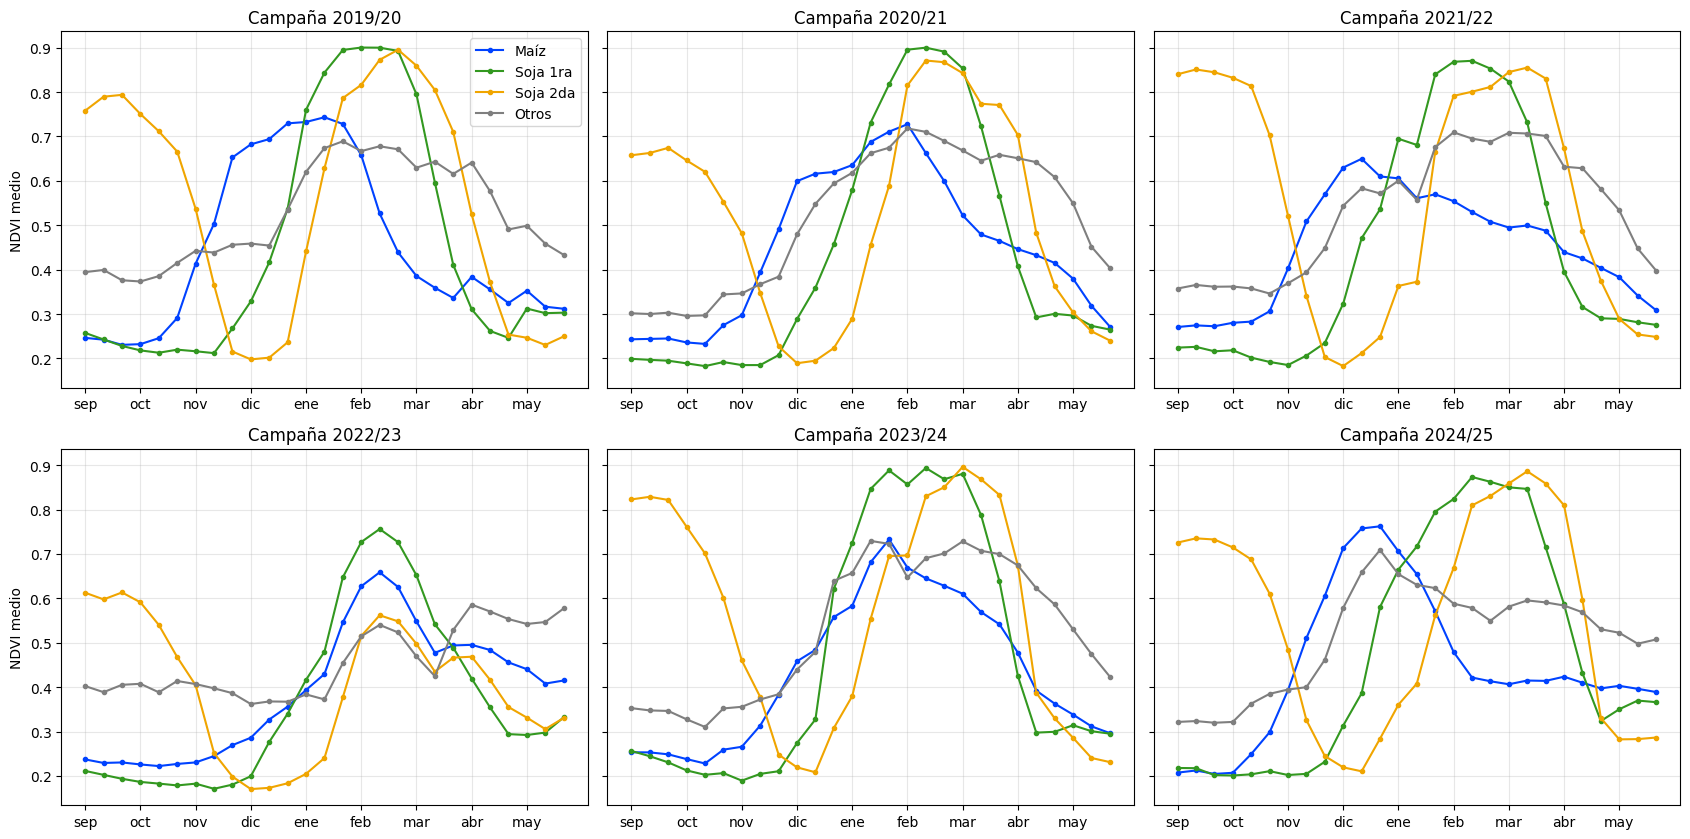

Clima medio de los puntos por campaña:
         lluvia sep-may (mm)  tmax media (°C)
campaña                                      
2019_20           714.500000        26.100000
2020_21           697.599976        25.700001
2021_22           583.299988        25.799999
2022_23           484.500000        27.600000
2023_24           845.000000        25.100000
2024_25           728.299988        26.799999


In [28]:
import matplotlib.pyplot as plt

b4, b8 = BANDAS.index('B4'), BANDAS.index('B8')
ndvi = np.zeros((N, T), np.float32)
for i in range(0, N, 1000):
    x = X[i:i + 1000].astype(np.float32)
    ndvi[i:i + 1000] = ((x[..., b8] - x[..., b4]) / (x[..., b8] + x[..., b4] + 1e-6)).mean(axis=(2, 3))

colores = {0: '#0042ff', 1: '#339820', 2: '#f0a500', 3: '#7f7f7f'}
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5), sharey=True)
for ax, camp in zip(axes.ravel(), CAMPANAS):
    for k, nombre in CLASES.items():
        sel = ((puntos.campana == camp) & (puntos.clase == k)).values
        if sel.any():
            ax.plot(range(T), ndvi[sel].mean(axis=0), marker='.', color=colores[k], label=nombre)
    ax.set_xticks(range(0, T, 3)); ax.set_xticklabels(['sep', 'oct', 'nov', 'dic', 'ene', 'feb', 'mar', 'abr', 'may'])
    ax.set_title(f'Campaña {camp.replace("_", "/")}'); ax.grid(alpha=.3)
axes[0, 0].set_ylabel('NDVI medio'); axes[1, 0].set_ylabel('NDVI medio'); axes[0, 0].legend()
plt.tight_layout(); plt.show()

lluvia = pd.DataFrame({'campaña': puntos.campana, 'lluvia sep-may (mm)': clima[:, :, 0].sum(axis=1),
                       'tmax media (°C)': clima[:, :, 2].mean(axis=1)})
print('Clima medio de los puntos por campaña:')
print(lluvia.groupby('campaña').mean().round(1).to_string())

## Siguiente paso

Con `dataset_v2/dataset_cultivos.npz` y `dataset_meta.csv`:
- el **notebook 03 (versión 2)** entrena la red solo con imágenes, validando por departamento y dejando un año afuera;
- el **notebook 04** suma el clima y compara contra el 03.